# this notebook is for model evaluation

In [93]:
%load_ext autoreload
%autoreload 2
import torch
import torch.optim as optim
import matplotlib.pyplot as plt
from pathlib import Path
from torchvision import datasets
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
from pet_breed_classifier.data import get_dataloaders
from pet_breed_classifier.model import get_model, get_criterion, get_predictions
from pet_breed_classifier.visualize import show_errors

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [31]:
root = Path("../data").resolve()
ft_lr_3e_minus5 = Path("../parameters/model2/parameters2.pt").resolve()
train_loader, val_loader, test_loader, classes = get_dataloaders(root)

device = torch.accelerator.current_accelerator() if torch.accelerator.is_available() else "cpu"

model = get_model(len(classes), device)

model.load_state_dict(torch.load(ft_lr_3e_minus5, map_location=device))

<All keys matched successfully>

test accuracy of the model above is 0.897, but this does not mean model is evenly good for every breed, that number is average for 37 classes so ir can be good for most of them but very bad for 2-3 breeds, so we have to check per-class metrics to be sure that model performes well on entire dataset

In [30]:
y_true, y_pred = get_predictions(model, test_loader, device)
print((y_true==y_pred).mean())

0.8967020986644862


In [35]:
print(classification_report(y_true, y_pred, target_names=classes, digits=3))

                            precision    recall  f1-score   support

                Abyssinian      0.880     0.827     0.853        98
          American Bulldog      0.674     0.890     0.767       100
 American Pit Bull Terrier      0.778     0.490     0.601       100
              Basset Hound      0.989     0.890     0.937       100
                    Beagle      0.910     0.910     0.910       100
                    Bengal      0.806     0.870     0.837       100
                    Birman      0.724     0.840     0.778       100
                    Bombay      0.911     0.932     0.921        88
                     Boxer      0.916     0.879     0.897        99
         British Shorthair      0.966     0.840     0.898       100
                 Chihuahua      0.862     0.940     0.900       100
              Egyptian Mau      0.936     0.907     0.921        97
    English Cocker Spaniel      0.941     0.950     0.945       100
            English Setter      0.969     0.930

                            precision    recall  f1-score   support

                Abyssinian      0.880     0.827     0.853        98
                
          American Bulldog      0.674     0.890     0.767       100
          
 American Pit Bull Terrier      0.778     0.490     0.601       100

              Basset Hound      0.989     0.890     0.937       100
              
                    Beagle      0.910     0.910     0.910       100
                    
                    Bengal      0.806     0.870     0.837       100
                    
                    Birman      0.724     0.840     0.778       100
                    
                    Bombay      0.911     0.932     0.921        88
                    
                     Boxer      0.916     0.879     0.897        99
                     
         British Shorthair      0.966     0.840     0.898       100
         
                 Chihuahua      0.862     0.940     0.900       100
                 
              Egyptian Mau      0.936     0.907     0.921        97
              
    English Cocker Spaniel      0.941     0.950     0.945       100
    
            English Setter      0.969     0.930     0.949       100
            
        German Shorthaired      0.874     0.970     0.919       100
        
            Great Pyrenees      0.989     0.920     0.953       100
            
                  Havanese      0.906     0.960     0.932       100
                  
             Japanese Chin      0.990     0.990     0.990       100
             
                  Keeshond      1.000     1.000     1.000        99
                  
                Leonberger      0.971     0.990     0.980       100
                
                Maine Coon      0.842     0.800     0.821       100
                
        Miniature Pinscher      0.976     0.820     0.891       100
        
              Newfoundland      0.970     0.980     0.975       100
              
                   Persian      0.871     0.880     0.876       100
                   
                Pomeranian      0.968     0.900     0.933       100
                
                       Pug      0.970     0.980     0.975       100
                       
                   Ragdoll      0.688     0.770     0.726       100
                   
              Russian Blue      0.930     0.930     0.930       100
              
             Saint Bernard      0.951     0.970     0.960       100
             
                   Samoyed      0.961     0.980     0.970       100
                   
          Scottish Terrier      0.916     0.990     0.951        99
          
                 Shiba Inu      0.839     0.990     0.908       100
                 
                   Siamese      0.951     0.780     0.857       100
                   
                    Sphynx      0.948     0.920     0.934       100
                    
Staffordshire Bull Terrier      0.612     0.674     0.642        89

           Wheaten Terrier      0.979     0.930     0.954       100
           
         Yorkshire Terrier      0.969     0.940     0.954       100

                  accuracy                          0.897      3669
                  
                 macro avg      0.901     0.896     0.896      3669
                 
              weighted avg      0.902     0.897     0.897      3669

we can see that errors are concantrated, we have lowest scores for dogs for these classes: American Bulldog, American Pit Bull Terrier, Staffordshire Bull Terrier and for cats: Ragdoll and Birman, those breeds are visually similar so it is nantural that model makes mistakes there. f1 score here are low(0.60-0.78) but we have 20 breeds that exceed 93% so we can say that overall performance of the model is acceptable

macro and weighted averages  are almost identical because dataset is class balanced

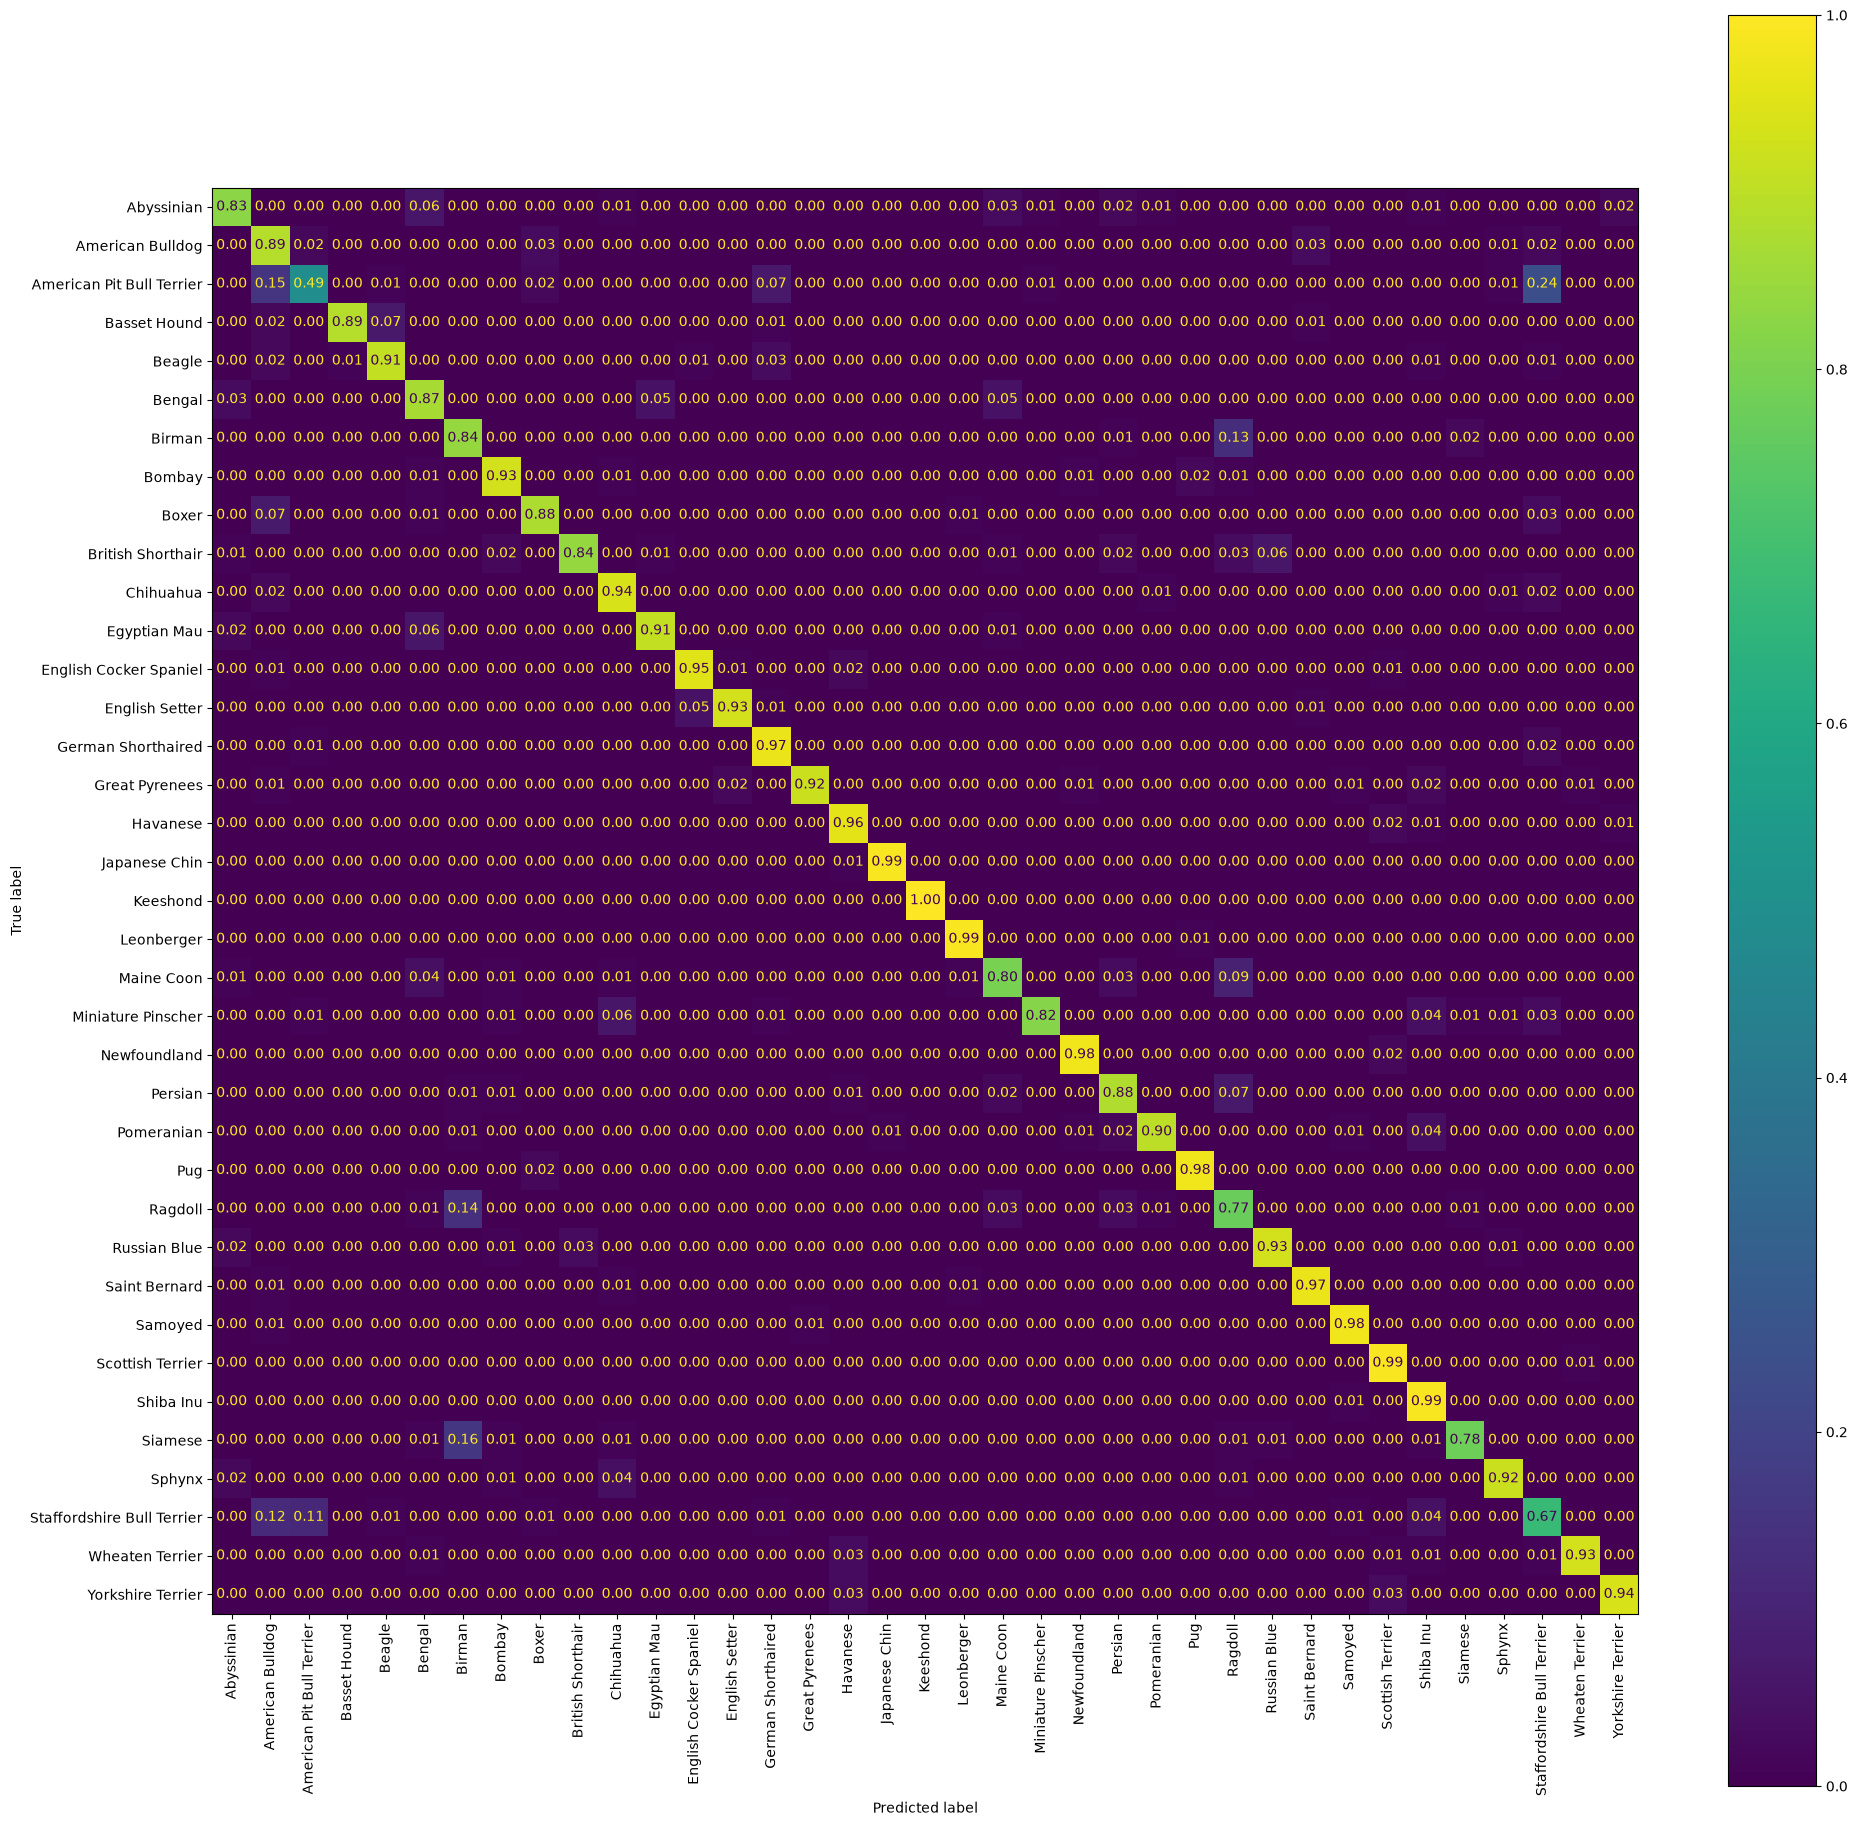

In [48]:
fig, ax = plt.subplots(1, 1, figsize=(23, 23))
print(ConfusionMatrixDisplay.from_predictions(y_true, y_pred, normalize="true", display_labels=classes, xticks_rotation=90, ax = ax, values_format=".2f"))

American Pit Bull Terrier is mostly mistaken for Staffordshire Bull Terrier(24%) and American Bulldog(15%), German Shorthaired(7%)
Staffordshire Bull Terrier is ebenly mistaken for American Bulldog(12%) and American Pit Bull Terrier(11%)
American Bulldog has pretty good recall, low precision means it is absorbing other two, but it also absorbs Boxer

so  for dog main problem is differentiating between American Pit Bull Terrier and Staffordshire Bull Terrier, but when it is not sure it selects "default class"  - American Bulldog

Birman,Persian and Maine coon is mistaken for Ragdoll, and Ragdoll and Siamese are almost equally mistaken for Birman

so model struggles to differentiate Birman and Ragdoll. but when it is not sure it selects "default class"  - Ragdoll


we also have second mini cluster for cats: Abyssinian, Bengal, Egyptian Mau

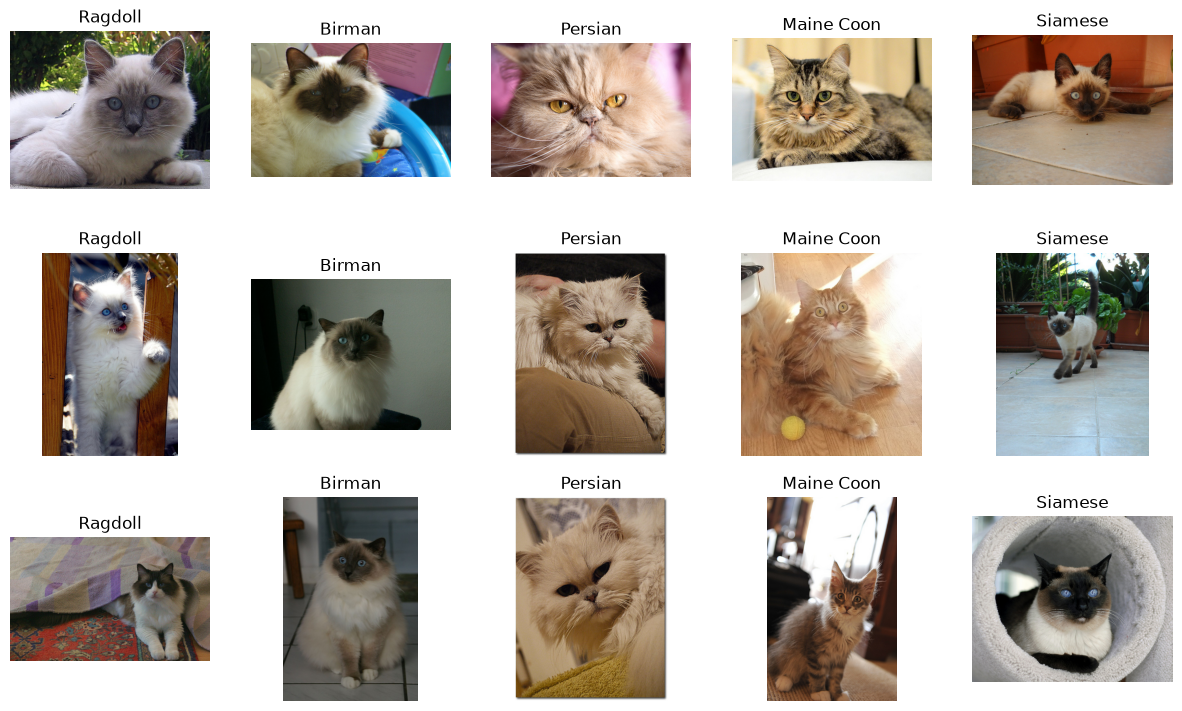

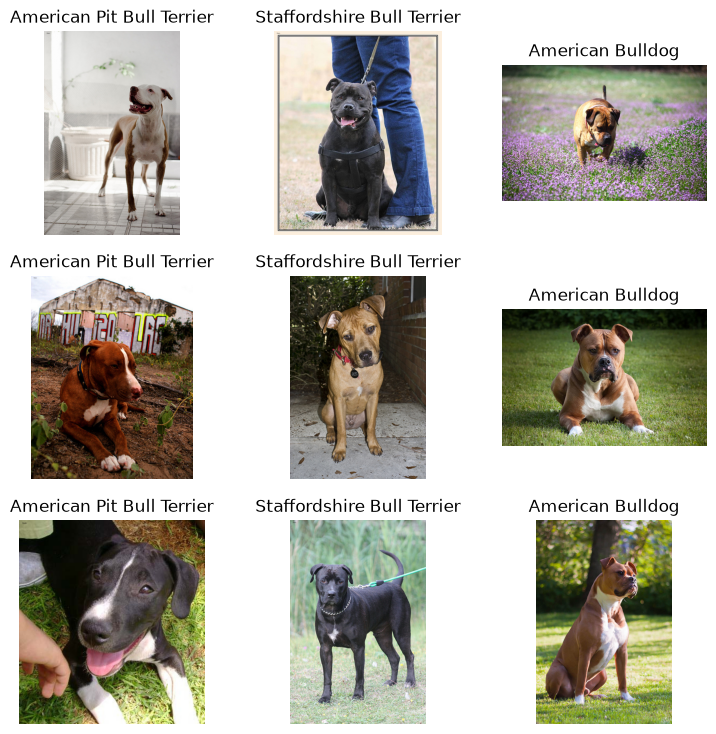

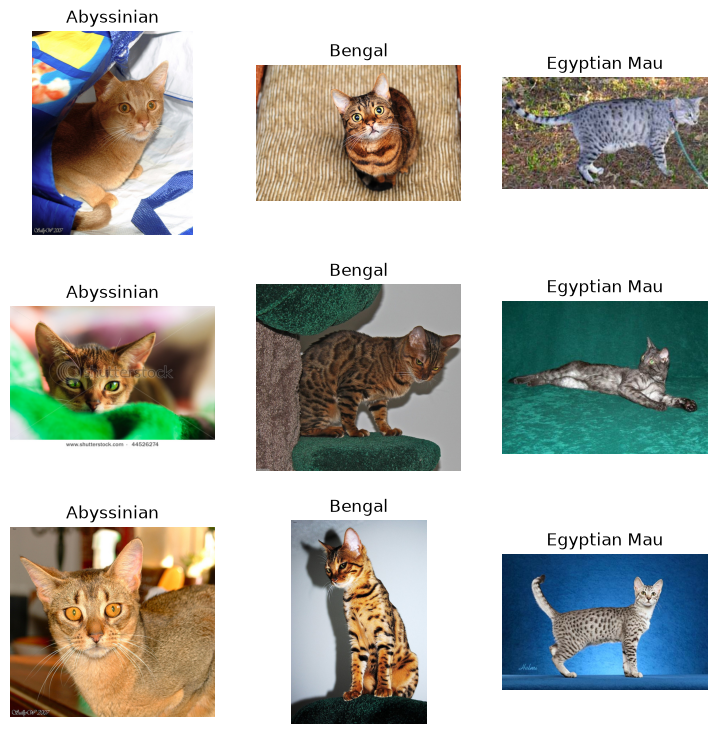

In [90]:
root = Path("../data").resolve()
raw = datasets.OxfordIIITPet(root, split="trainval")

names = ["Ragdoll", "Birman", "Persian", "Maine Coon", "Siamese", "American Pit Bull Terrier",  "Staffordshire Bull Terrier", "American Bulldog", "Abyssinian", "Bengal", "Egyptian Mau"]
samples = {name : [] for name in names}

for img, label in raw:
    name = raw.classes[label]
    if name in samples and len(samples[name]) < 3:
        samples[name].append(img)
    if all(len(v) == 3 for v in samples.values()):
        break
        
fig, ax = plt.subplots(3, 5, figsize=(15, 9))
for i in range(3):
    ax[i, 0].imshow(ragdoll[i][0])
    ax[i, 0].set_title("Ragdoll")
    ax[i, 0].axis("off")

    ax[i, 1].imshow(birman[i][0])
    ax[i, 1].set_title("Birman")
    ax[i, 1].axis("off")

    ax[i, 2].imshow(persian[i][0])
    ax[i, 2].set_title("Persian")
    ax[i, 2].axis("off")

    ax[i, 3].imshow(maine[i][0])
    ax[i, 3].set_title("Maine Coon")
    ax[i, 3].axis("off")

    ax[i, 4].imshow(siamese[i][0])
    ax[i, 4].set_title("Siamese")
    ax[i, 4].axis("off")

fig1, ax1 = plt.subplots(3, 3, figsize=(9, 9))
for i in range(3):
    ax1[i, 0].imshow(pit_bull[i][0])
    ax1[i, 0].set_title("American Pit Bull Terrier")
    ax1[i, 0].axis("off")

    ax1[i, 1].imshow(Staffordshire[i][0])
    ax1[i, 1].set_title("Staffordshire Bull Terrier")
    ax1[i, 1].axis("off")

    ax1[i, 2].imshow(bulldog[i][0])
    ax1[i, 2].set_title("American Bulldog")
    ax1[i, 2].axis("off")

fig2, ax2 = plt.subplots(3, 3, figsize=(9, 9))
for i in range(3):
    ax2[i, 0].imshow(abyssinian[i][0])
    ax2[i, 0].set_title("Abyssinian")
    ax2[i, 0].axis("off")

    ax2[i, 1].imshow(bengal[i][0])
    ax2[i, 1].set_title("Bengal")
    ax2[i, 1].axis("off")

    ax2[i, 2].imshow(egyptian[i][0])
    ax2[i, 2].set_title("Egyptian Mau")
    ax2[i, 2].axis("off")


#### visually similar breed groups

as we can see there are variations among same breed and different breeds share many characteristics, so it is natural that model makes mistakes here

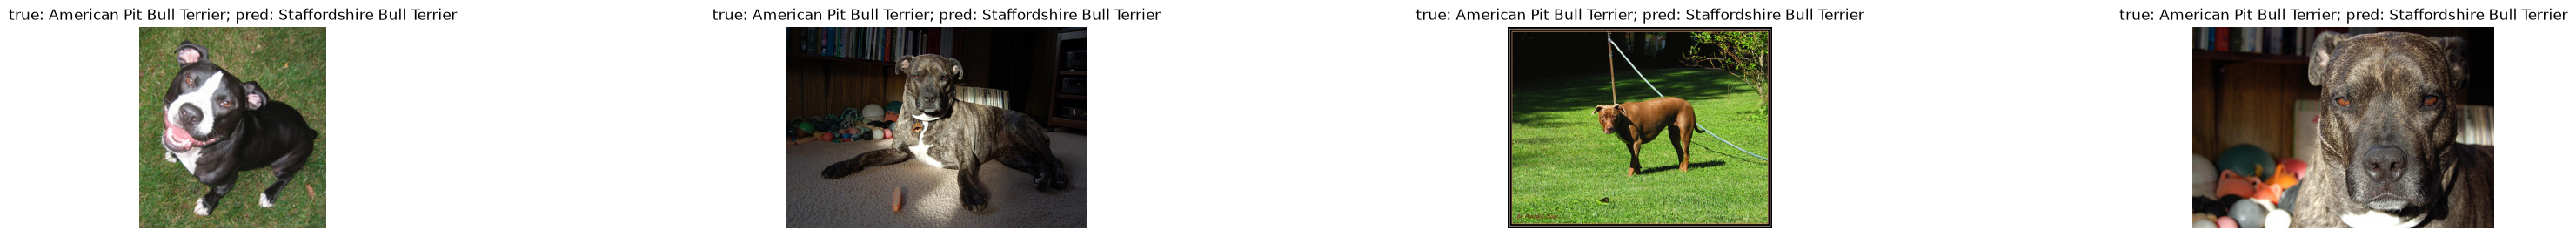

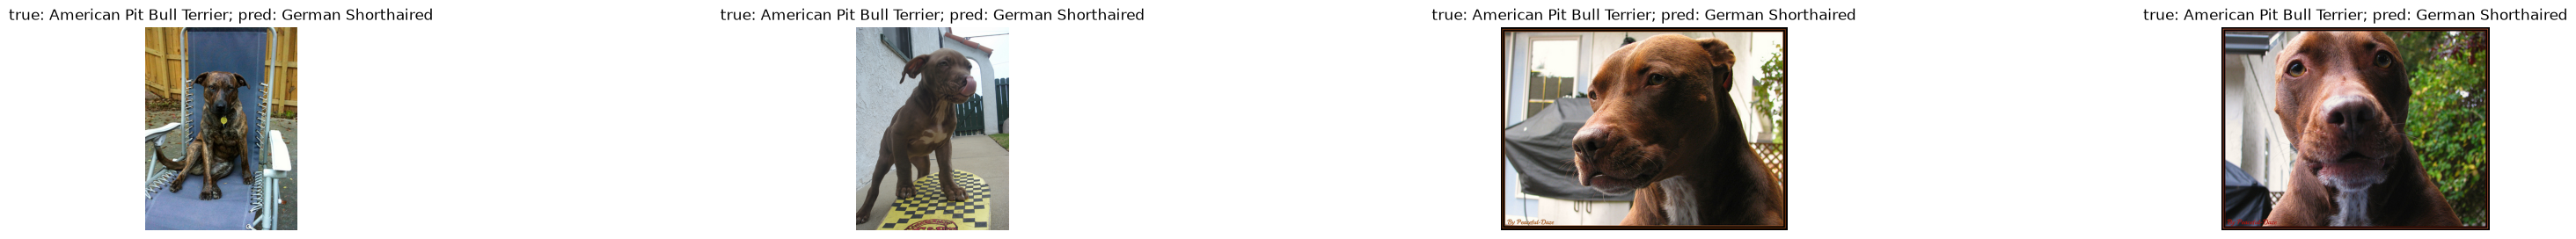

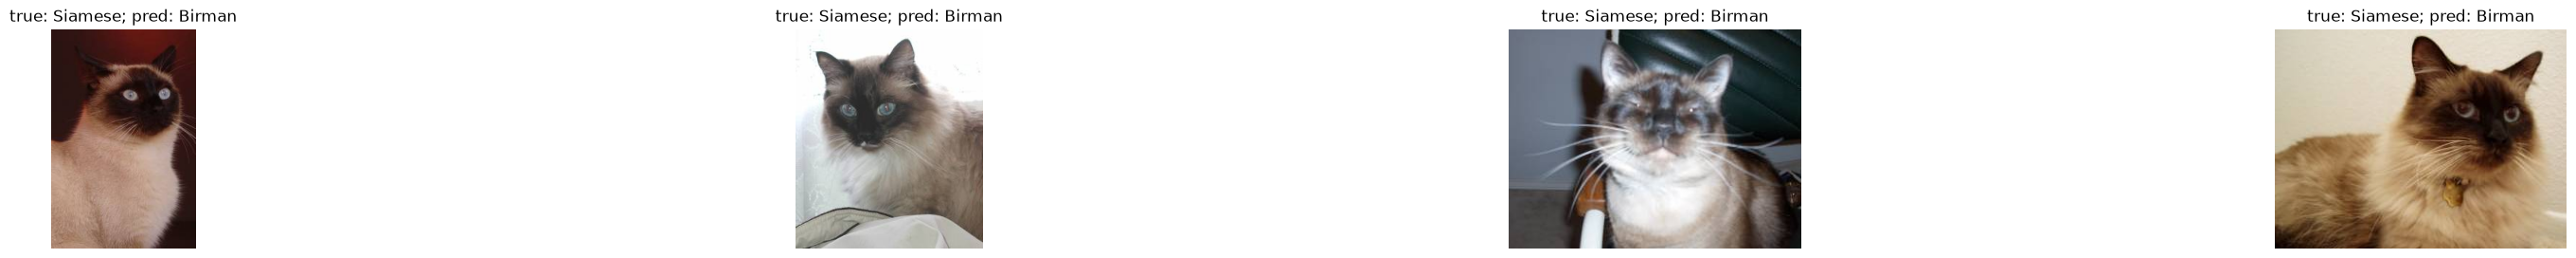

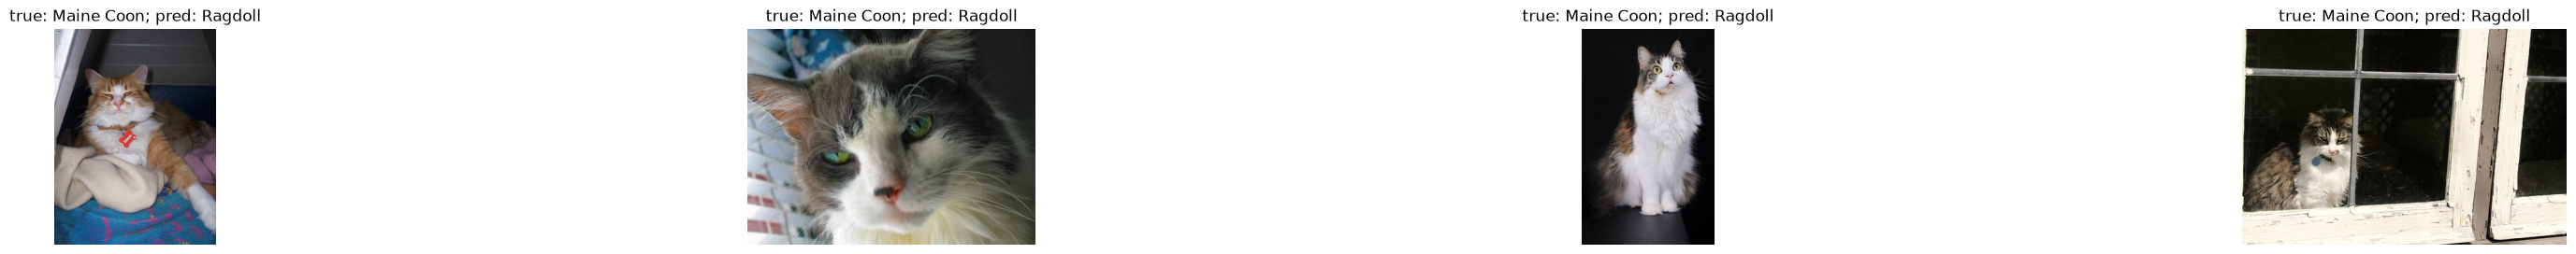

In [94]:
raw_test = datasets.OxfordIIITPet(root, split="test")

show_errors(raw_test, y_true, y_pred,  "American Pit Bull Terrier", "Staffordshire Bull Terrier")
show_errors(raw_test, y_true, y_pred,  "American Pit Bull Terrier", "German Shorthaired")
show_errors(raw_test, y_true, y_pred,  "Siamese", "Birman")
show_errors(raw_test, y_true, y_pred,  "Maine Coon", "Ragdoll")

as we can see confused images share coat color with predicted breed, for example Pit Bulls predicted as German Shorthaired are solid brown, Maine Coons predicted as Ragdoll have long hair and white chests. this suggest if shapes is not very clear model will rely on color.

many errors are because photos are close up faces, distant animals or objeect partially covering animal.

many of this cases would be hard for non-expert human too to tell them apart.